# Two Sides of Bologna's Airbnb Market
### Unit 3 Final Project: Exploratory Data Analysis
**Khalid Alotaibi**

This notebook explores every Airbnb listing in Bologna, Italy, from two points of view:

- **The host:** if I list a property in Bologna, what should I do?
- **The guest:** if I visit Bologna, where should I stay and what will I pay?

**Contents:** 1. Introduction, 2. Loading the data, 3. Data structure, 4. Data cleaning, 5. EDA (host, guest, correlations, univariate, bivariate and multivariate), 6. Price prediction model, 7. Insights summary, 8. Final summary

## 1. Introduction

### 1.1 Dataset

| | |
|---|---|
| **Title** | Inside Airbnb, Bologna listings (summary file `listings.csv`) |
| **Source** | [insideairbnb.com/get-the-data](https://insideairbnb.com/get-the-data/), Bologna, `listings.csv` |
| **Snapshot date** | 19 September 2026 |
| **Size** | 5,094 rows and 19 columns |

**Description:** Inside Airbnb is an independent project that collects public data about Airbnb listings in cities around the world. This file has every Airbnb listing in Bologna, Italy, on 19 September 2026. Each row is one listing with its price per night, room type, neighbourhood, location, host and reviews.

**Why I chose it:** the data is recent (2026), real and messy. It has missing values, duplicate listings and extreme prices, so it needs real cleaning. It also answers questions for two audiences: hosts and guests.

### 1.2 Problem definition

**What is the dataset about?** The short-term rental market in Bologna: who offers the listings, where they are, how much they cost and how popular they are.

**Main questions**

| Host questions | Guest questions |
|---|---|
| **H1.** Who controls the market: single hosts or professionals (more than 10 listings)? | **G1.** What does a typical night cost? |
| **H2.** Do professional hosts charge more? | **G2.** Which neighbourhoods are cheapest and which are most expensive? |
| **H3.** Where is the competition strongest? | **G3.** How much more is an entire home than a private room? |
| **H4.** Which price range gets the most demand? | **G4.** Can I find short stays? |
| **H5.** Does a higher price mean less demand? | **G5.** Where are the listings on the map? |

**How I measure demand:** the data has no booking numbers, so I use the **reviews in the last 12 months** (`number_of_reviews_ltm`). More reviews usually means more guests.

**What I expect:** the city centre will be the most expensive area, entire homes will cost more than private rooms, and hosts with many listings will hold a big part of the market.

## 2. Loading the data

In [1]:
# import the libraries and set the chart style
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

# colours used in the charts
coral = "#FF5A5F"
dark = "#484848"
tan = "#B07D52"
grey = "#9A9A9A"
teal = "#2A9D8F"
host_colors = [coral, tan, dark]
price_colors = [teal, coral, dark]
room_colors = {"Entire home/apt": coral, "Private room": dark, "Shared room": tan, "Hotel room": grey}

In [2]:
# load the data straight from the inside airbnb link
url = "https://data.insideairbnb.com/italy/emilia-romagna/bologna/2026-09-19/visualisations/listings.csv"
df = pd.read_csv(url)
print("rows:", df.shape[0], "columns:", df.shape[1])

rows: 5094 columns: 19


In [3]:
# only if the link stops working: remove the # from the 3 lines below and upload listings.csv
# from google.colab import files
# files.upload()
# df = pd.read_csv("listings.csv")

## 3. Data structure

In [4]:
# first 5 rows
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,46352,A room in Pasolini's house,467810,1462512014511075666,Eleonora,NaN,Porto - Saragozza,44.49163,11.33398,Private room,71.0,2.0,498,2026-06-16,2.56,2,68,18,IT037006C1C1767
1,59697,COZY LARGE BEDROOM in the city center,286688,1462514723624893932,Paolo,NaN,Santo Stefano,44.48817,11.34124,Private room,29.0,31.0,243,2025-12-21,1.45,2,299,1,NaN
2,85368,Garden House Bologna,467675,1462519120258743480,Anna Maria,NaN,Santo Stefano,44.47888,11.35625,Entire home/apt,201.0,2.0,71,2026-06-18,0.40,1,244,7,IT037006C2QKQSH3S7
3,219878,Top floor with elevator for Long and Short Stays,1139326,1462516187476852110,Eli,NaN,Santo Stefano,44.48787,11.35392,Entire home/apt,181.0,3.0,199,2026-06-01,1.10,1,308,14,IT037006C2HQERHOGR
4,229114,Apartment with terrace between center and fair,1196205,1462539440588872403,Davide,NaN,Navile,44.51072,11.34957,Entire home/apt,205.0,1.0,113,2026-08-05,0.67,1,334,14,IT037006C2KRRTWGRT


Each row is one listing. `price` is the price per night in euros and `number_of_reviews_ltm` is the number of reviews in the last 12 months.

In [5]:
# number of rows and columns
df.shape

(5094, 19)

The raw file has **5,094 rows** and **19 columns**.

In [6]:
# column types and non null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5094 entries, 0 to 5093
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              5094 non-null   int64  
 1   name                            5094 non-null   str    
 2   host_id                         5094 non-null   int64  
 3   host_profile_id                 5094 non-null   int64  
 4   host_name                       5094 non-null   str    
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   5094 non-null   str    
 7   latitude                        5094 non-null   float64
 8   longitude                       5094 non-null   float64
 9   room_type                       5094 non-null   str    
 10  price                           4576 non-null   float64
 11  minimum_nights                  4934 non-null   float64
 12  number_of_reviews               5094 non-null

Most columns are numbers (`int64`, `float64`) or text (`object`, shown as `str` in newer pandas). `last_review` is text, so it will be converted to a date. Some columns have fewer than 5,094 values, which means they have missing values.

In [7]:
# statistics of the numeric columns
df.describe()

,id,host_id,host_profile_id,neighbourhood_group,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
count,5.094000e+03,5.094000e+03,5.094000e+03,0.0,5094.000000,5094.000000,4576.000000,4934.000000,5094.000000,4555.000000,5094.000000,5094.000000,5094.000000
mean,8.430050e+17,3.025298e+16,1.478924e+18,NaN,44.497867,11.344034,224.031687,4.759830,65.025324,1.665328,16.987436,173.310561,14.069690
std,6.501426e+17,2.256446e+17,4.620103e+16,NaN,0.010538,0.020091,284.256490,13.478489,105.255479,1.730010,30.681644,119.357532,19.026474
min,4.635200e+04,3.846800e+04,1.462507e+18,NaN,44.443850,11.237330,16.000000,1.000000,0.000000,0.010000,1.000000,0.000000,0.000000
25%,4.295940e+07,5.564946e+07,1.463229e+18,NaN,44.492280,11.337440,128.000000,1.000000,5.000000,0.400000,1.000000,65.000000,1.000000
50%,9.839424e+17,2.180075e+08,1.468255e+18,NaN,44.497214,11.344655,177.000000,1.000000,23.000000,1.080000,3.000000,163.000000,6.000000
75%,1.428849e+18,5.042057e+08,1.470233e+18,NaN,44.502890,11.352688,252.000000,2.000000,79.000000,2.350000,16.000000,286.000000,21.000000
max,1.777606e+18,1.776966e+18,1.776967e+18,NaN,44.551392,11.419208,10000.000000,365.000000,1099.000000,12.960000,136.000000,365.000000,148.000000


The median `price` is **€177** but the maximum is **€10,000**, so there are extreme outliers. `minimum_nights` also goes up to **365** nights.

In [8]:
# missing values in each column
df.isnull().sum()

id                                   0
name                                 0
host_id                              0
host_profile_id                      0
host_name                            0
neighbourhood_group               5094
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                              518
minimum_nights                     160
number_of_reviews                    0
last_review                        539
reviews_per_month                  539
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                            750
dtype: int64

| Column | Missing | What it means |
|---|---|---|
| `neighbourhood_group` | 5,094 | completely empty |
| `license` | 750 | no license number shown |
| `last_review`, `reviews_per_month` | 539 each | probably listings with no reviews (checked in 4.4) |
| `price` | 518 | no price shown |
| `minimum_nights` | 160 | no minimum stay shown |

## 4. Data cleaning

Every step prints the shape before and after, so we can see what changed.

### 4.1 Drop columns we do not need
`neighbourhood_group` is completely empty, and `host_profile_id` and `host_name` are not needed because we already have `host_id`.

In [9]:
# drop the empty column and the columns we do not need
print("before:", df.shape)
df = df.drop(columns=["neighbourhood_group", "host_profile_id", "host_name"])
print("after:", df.shape)

before: (5094, 19)
after: (5094, 16)


### 4.2 Remove duplicates
First we look for rows that are fully identical, then we check again without the `id`, because the same listing can be posted twice with a different id.

In [10]:
# check full duplicates and duplicates when we ignore the id
cols_without_id = df.columns.drop("id")
print("full duplicates:", df.duplicated().sum())
print("duplicates without id:", df.duplicated(subset=cols_without_id).sum())

full duplicates: 0
duplicates without id: 2


In [11]:
# show both copies of each duplicate
df[df.duplicated(subset=cols_without_id, keep=False)].sort_values("name")

,id,name,host_id,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
1793,635173755592341423,"Affittacamere Debre Mariam, Camera doppia",309500606,Santo Stefano,44.479095,11.324224,Private room,75.0,NaN,50,2026-09-14,0.96,8,0,21,NaN
1794,635175111779136531,"Affittacamere Debre Mariam, Camera doppia",309500606,Santo Stefano,44.479095,11.324224,Private room,75.0,NaN,50,2026-09-14,0.96,8,0,21,NaN
4421,1622383149310044797,BolognaFiere · Camera con terrazzo e bagno pri...,746503888,San Donato - San Vitale,44.506173,11.360582,Private room,201.0,NaN,6,2026-09-10,0.85,3,0,6,NaN
4437,1624541689924159945,BolognaFiere · Camera con terrazzo e bagno pri...,746503888,San Donato - San Vitale,44.506173,11.360582,Private room,201.0,NaN,6,2026-09-10,0.85,3,0,6,NaN


In [12]:
# keep the first copy of each duplicate
print("before:", df.shape)
df = df.drop_duplicates(subset=cols_without_id)
print("after:", df.shape)

before: (5094, 16)
after: (5092, 16)


There are no fully identical rows, but **2 listings were posted twice** (same host, name, price and location, different id). We keep the first copy of each.

### 4.3 Missing prices
Price is the main column of this project, and guessing 518 prices would change the results, so these rows are removed.

In [13]:
# remove the listings with no price
print("missing prices:", df["price"].isnull().sum())
df = df.dropna(subset=["price"])
print("after:", df.shape)

missing prices: 518
after: (4574, 16)


### 4.4 Missing reviews_per_month and last_review
If a listing was never reviewed, it has no last review date and no reviews per month. Let's check that.

In [14]:
# check that the missing values are the listings with 0 reviews
missing = df["reviews_per_month"].isnull()
no_reviews = df["number_of_reviews"] == 0
print("missing reviews_per_month:", missing.sum())
print("listings with 0 reviews:", no_reviews.sum())
print("both at the same time:", (missing & no_reviews).sum())

missing reviews_per_month: 460
listings with 0 reviews: 460
both at the same time: 460


The three numbers are the same, so the missing values are listings with **0 reviews** and the right value for `reviews_per_month` is **0**. For `last_review` we change the text to a date and keep the missing ones empty, because "never reviewed" is real information.

In [15]:
# fill reviews_per_month with 0 and change last_review to a date
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df["last_review"] = pd.to_datetime(df["last_review"])
print("missing reviews_per_month:", df["reviews_per_month"].isnull().sum())
print("last_review type:", df["last_review"].dtype)

missing reviews_per_month: 0
last_review type: datetime64[us]


### 4.5 Missing minimum_nights
Only a few listings miss this value, so we fill it with the **median**, which is not affected by outliers like 365 nights.

In [16]:
# fill minimum_nights with the median
print("missing:", df["minimum_nights"].isnull().sum())
print("median:", df["minimum_nights"].median())
df["minimum_nights"] = df["minimum_nights"].fillna(df["minimum_nights"].median()).astype(int)
print("missing now:", df["minimum_nights"].isnull().sum())

missing: 150
median: 1.0
missing now: 0


### 4.6 Price outliers

In [17]:
# look at the price statistics and count the listings above 1000
print(df["price"].describe())
print("listings above 1000:", (df["price"] > 1000).sum())

count     4574.000000
mean       224.069305
std        284.309895
min         16.000000
25%        128.000000
50%        177.000000
75%        252.000000
max      10000.000000
Name: price, dtype: float64
listings above 1000: 44


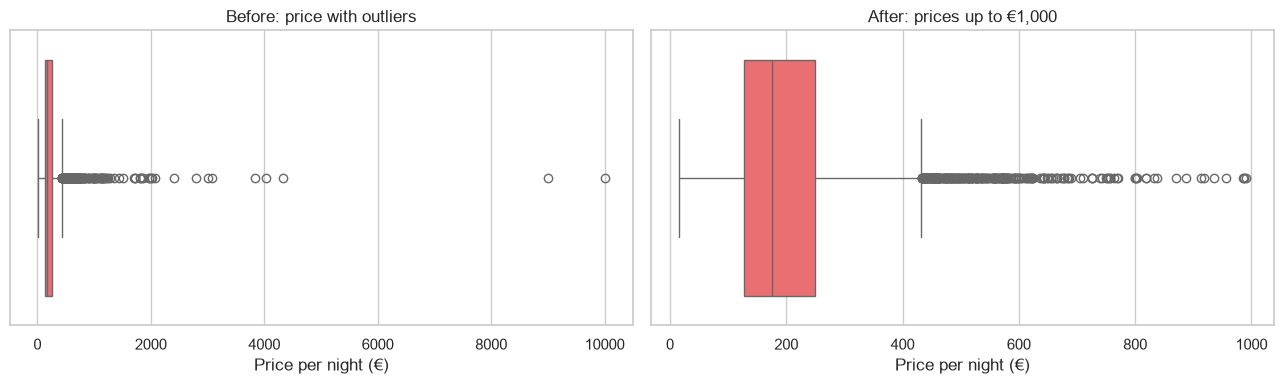

In [18]:
# boxplot of the price before and after removing the outliers
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df["price"], ax=axes[0], color=coral)
axes[0].set_title("Before: price with outliers")
axes[0].set_xlabel("Price per night (€)")
sns.boxplot(x=df.loc[df["price"] <= 1000, "price"], ax=axes[1], color=coral)
axes[1].set_title("After: prices up to €1,000")
axes[1].set_xlabel("Price per night (€)")
plt.tight_layout()
plt.show()

**Figure 1: price before and after removing outliers.** A few listings ask up to €10,000 a night, which squeezes the whole box to the left. Only 44 listings (under 1%) cost more than €1,000, but they would distort the averages, so we remove them.

In [19]:
# remove the listings above 1000 a night
df = df[df["price"] <= 1000]
print("after:", df.shape)

after: (4530, 16)


### 4.7 Rename columns

In [20]:
# give two long columns simpler names
df = df.rename(columns={"calculated_host_listings_count": "host_listings_count",
                        "number_of_reviews_ltm": "reviews_last_12m"})
df.columns.tolist()

['id',
 'name',
 'host_id',
 'neighbourhood',
 'latitude',
 'longitude',
 'room_type',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'last_review',
 'reviews_per_month',
 'host_listings_count',
 'availability_365',
 'reviews_last_12m',
 'license']

### 4.8 New columns

| New column | Rule | Used for |
|---|---|---|
| `host_type` | 1 listing = Single, 2 to 10 = Small, more than 10 = Professional | host |
| `has_license` | True if the listing shows a license number | host |
| `price_category` | under €100 = Budget, €100 to €199 = Mid-range, €200 or more = Premium | host and guest |
| `stay_type` | minimum stay of 30 nights or more = Long-term, otherwise Short-term | guest |

After `has_license` is made, the `license` column is not needed anymore.

In [21]:
# make the 4 new columns
df["host_type"] = pd.cut(df["host_listings_count"], bins=[0, 1, 10, np.inf],
                         labels=["Single", "Small (2-10)", "Professional (11+)"])

df["has_license"] = df["license"].notnull()
df = df.drop(columns=["license"])

# right=False puts 100 in mid-range and 200 in premium
df["price_category"] = pd.cut(df["price"], bins=[0, 100, 200, np.inf], right=False,
                              labels=["Budget (<€100)", "Mid-range (€100-199)", "Premium (€200+)"])

df["stay_type"] = np.where(df["minimum_nights"] >= 30, "Long-term (30+ nights)", "Short-term")

df[["host_listings_count", "host_type", "has_license", "price", "price_category", "minimum_nights", "stay_type"]].head()

,host_listings_count,host_type,has_license,price,price_category,minimum_nights,stay_type
0,2,Small (2-10),True,71.0,Budget (<€100),2,Short-term
1,2,Small (2-10),False,29.0,Budget (<€100),31,Long-term (30+ nights)
2,1,Single,True,201.0,Premium (€200+),2,Short-term
3,1,Single,True,181.0,Mid-range (€100-199),3,Short-term
4,1,Single,True,205.0,Premium (€200+),1,Short-term


### 4.9 Final check and save

In [22]:
# final check: shape, missing values, duplicates and max price
print("shape:", df.shape)
print(df.isnull().sum())
print("duplicates:", df.duplicated(subset=df.columns.drop("id")).sum())
print("max price:", df["price"].max())

shape: (4530, 19)
id                       0
name                     0
host_id                  0
neighbourhood            0
latitude                 0
longitude                0
room_type                0
price                    0
minimum_nights           0
number_of_reviews        0
last_review            448
reviews_per_month        0
host_listings_count      0
availability_365         0
reviews_last_12m         0
host_type                0
has_license              0
price_category           0
stay_type                0
dtype: int64
duplicates: 0
max price: 990.0


The only missing values left are in `last_review` (listings that were never reviewed), which we kept on purpose. There are no duplicates and no price above €1,000.

In [23]:
# save the clean data and download it (the download works in colab)
df.to_csv("clean_listings.csv", index=False)
print("saved clean_listings.csv with", len(df), "rows")

try:
    from google.colab import files
    files.download("clean_listings.csv")
except ImportError:
    print("not running in colab, the file is saved next to this notebook")

saved clean_listings.csv with 4530 rows
not running in colab, the file is saved next to this notebook


**Cleaning summary**

| Step | Rows left |
|---|---|
| Raw data | 5,094 |
| Removed 2 duplicate listings | 5,092 |
| Removed 518 listings with no price | 4,574 |
| Removed 44 price outliers (above €1,000) | **4,530** |

We also dropped 3 columns, filled `reviews_per_month` with 0 and `minimum_nights` with the median, changed `last_review` to a date, renamed 2 columns and added 4 new columns.

## 5. Exploratory Data Analysis (EDA)

- **Part A** looks at the market as a **host**.
- **Part B** looks at it as a **guest**.
- **Part C** checks the correlations between the numeric columns.
- **Part D** is the univariate analysis of the other columns: histograms, countplots and boxplots.
- **Part E** is more bivariate and multivariate analysis: a stacked bar plot, a scatter plot, a price heatmap and a pairplot.

Parts A to C are the charts used in the Streamlit dashboard. Parts D and E are extra EDA that is only in this notebook.

### 5A. Host perspective

#### H1. Who controls the market?

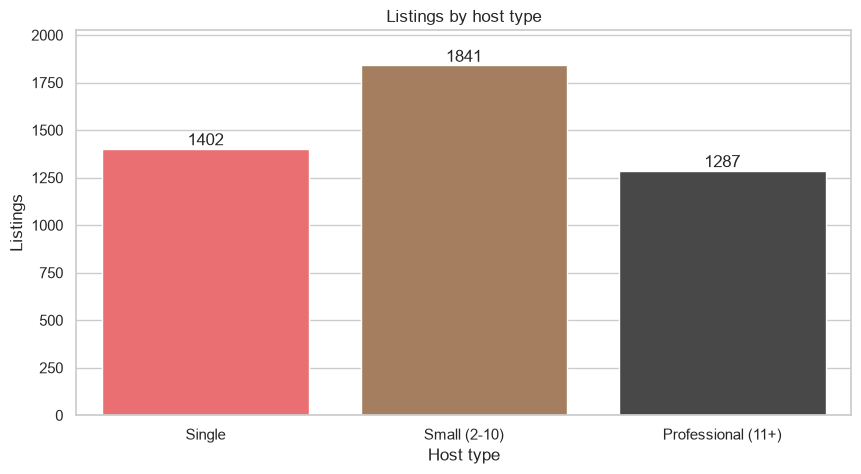

host_type
Small (2-10)          0.41
Single                0.31
Professional (11+)    0.28
Name: proportion, dtype: float64
hosts in each group:
host_type
Single                1402
Small (2-10)           593
Professional (11+)      48
Name: host_id, dtype: int64
total hosts: 2043


In [24]:
# count the listings of each host type
ax = sns.countplot(data=df, x="host_type", hue="host_type", palette=host_colors, legend=False, dodge=False)
for bars in ax.containers:
    ax.bar_label(bars)
ax.margins(y=0.1)
ax.set_title("Listings by host type")
ax.set_xlabel("Host type")
ax.set_ylabel("Listings")
plt.show()

print(df["host_type"].value_counts(normalize=True).round(2))
print("hosts in each group:")
print(df.groupby("host_type", observed=True)["host_id"].nunique())
print("total hosts:", df["host_id"].nunique())

**Figure 2: listings by host type.** Small hosts (2 to 10 listings) have the most listings: 1,841 (41%). Only **48 professional hosts**, about 2% of the 2,043 hosts, run **1,287 listings (28%)**. A very small group of hosts controls more than a quarter of the market.

#### H2. Do professional hosts charge more?

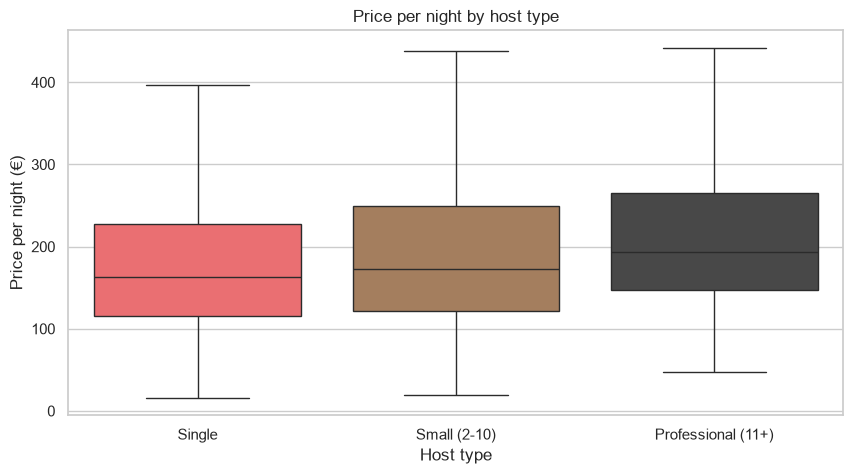

,listings,median_price,avg_reviews_12m
host_type,,,
Single,1402,163.0,17.4
Small (2-10),1841,173.0,14.9
Professional (11+),1287,194.0,12.9


In [25]:
# compare the price of each host type (outlier dots hidden)
ax = sns.boxplot(data=df, x="host_type", y="price", hue="host_type", palette=host_colors,
                 legend=False, dodge=False, showfliers=False)
ax.set_title("Price per night by host type")
ax.set_xlabel("Host type")
ax.set_ylabel("Price per night (€)")
plt.show()

df.groupby("host_type", observed=True).agg(listings=("price", "size"), median_price=("price", "median"),
                                           avg_reviews_12m=("reviews_last_12m", "mean")).round(1)

**Figure 3: price by host type.** The median price goes up with host size: **€163** for single hosts, **€173** for small hosts and **€194** for professionals, so professionals charge about **€31 more**. But single host listings get **17.4 reviews a year** on average against **12.9** for professionals.

#### H3. Where is the competition strongest?

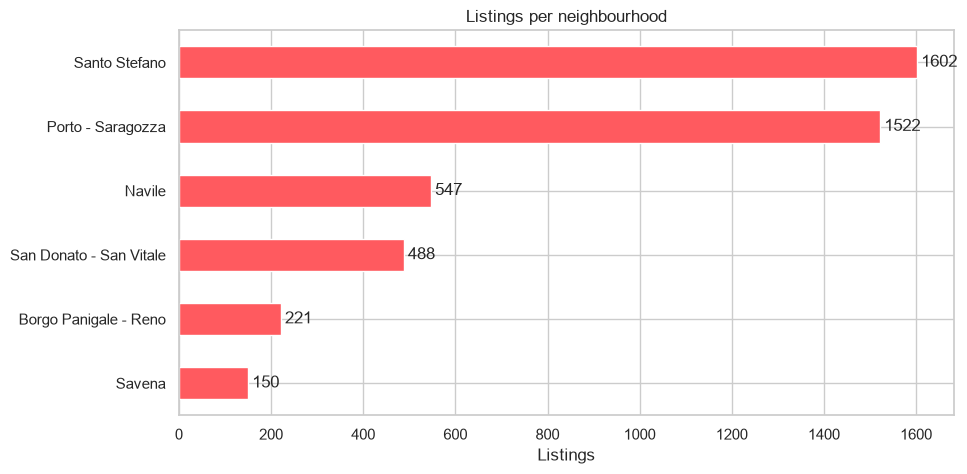

top 2 areas: 69 % of all listings


In [26]:
# count the listings in each neighbourhood
counts = df["neighbourhood"].value_counts()
ax = counts.sort_values().plot(kind="barh", color=coral)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Listings per neighbourhood")
ax.set_xlabel("Listings")
ax.set_ylabel("")
plt.show()

print("top 2 areas:", round(counts.iloc[:2].sum() / len(df) * 100), "% of all listings")

**Figure 4: listings per neighbourhood.** Santo Stefano (1,602) and Porto - Saragozza (1,522), the historic centre, hold **69%** of all listings, so this is where a new host faces the most competition. Savena (150) and Borgo Panigale - Reno (221) have the fewest.

#### H4. Which price range gets the most demand?

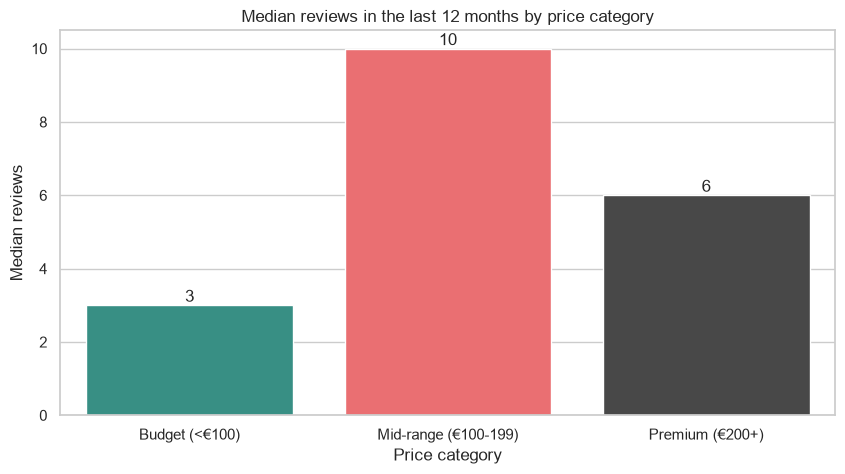

,count,median,mean
price_category,,,
Budget (<€100),573,3.0,14.2
Mid-range (€100-199),2156,10.0,17.2
Premium (€200+),1801,6.0,13.0


In [27]:
# median reviews in the last 12 months for each price category
ax = sns.barplot(data=df, x="price_category", y="reviews_last_12m", estimator="median", errorbar=None,
                 hue="price_category", palette=price_colors, legend=False, dodge=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f")
ax.set_title("Median reviews in the last 12 months by price category")
ax.set_xlabel("Price category")
ax.set_ylabel("Median reviews")
plt.show()

df.groupby("price_category", observed=True)["reviews_last_12m"].agg(["count", "median", "mean"]).round(1)

**Figure 5: demand by price category.** Mid-range listings (€100 to €199) get a median of **10 reviews a year**, premium listings 6 and budget listings only **3**. The cheapest listings are not the most popular: the mid-range is the sweet spot.

#### H5. Does a higher price mean less demand?

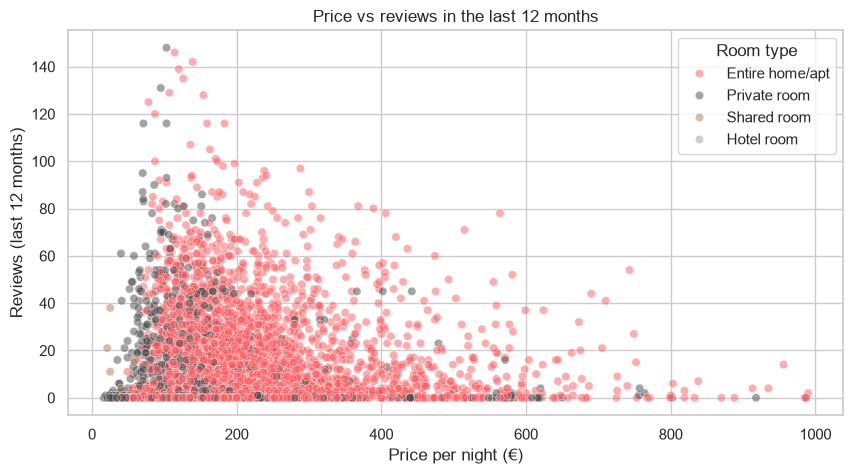

correlation: -0.09
listings with a license: 87 %


In [28]:
# price against reviews in the last 12 months
ax = sns.scatterplot(data=df, x="price", y="reviews_last_12m", hue="room_type", alpha=0.5,
                     hue_order=list(room_colors), palette=room_colors)
ax.set_title("Price vs reviews in the last 12 months")
ax.set_xlabel("Price per night (€)")
ax.set_ylabel("Reviews (last 12 months)")
ax.legend(title="Room type")
plt.show()

print("correlation:", round(df["price"].corr(df["reviews_last_12m"]), 2))
print("listings with a license:", round(df["has_license"].mean() * 100), "%")

**Figure 6: price vs demand.** The listings with the most reviews mostly cost under €300, but the correlation is only **-0.09**, which is almost zero. Price alone does not decide demand: location, room type and the host matter too. Also, **87%** of the listings show a license number.

### 5B. Guest perspective

#### G1. What does a typical night cost?

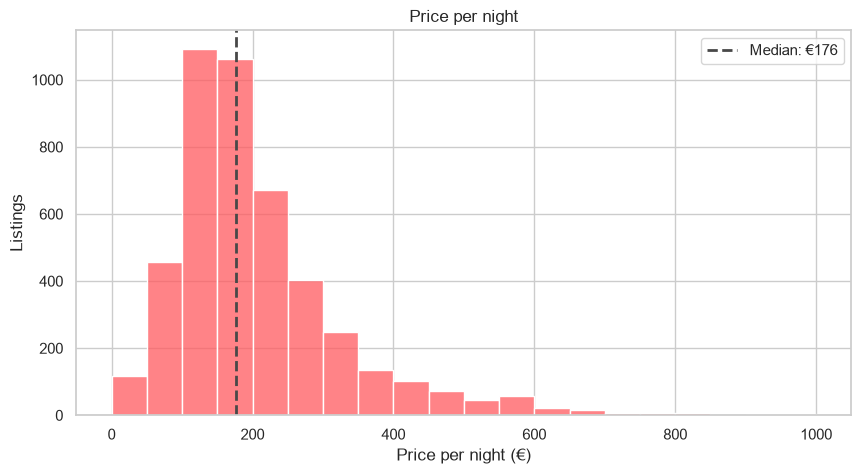

median: 176.0
mean: 206.0
middle 50%: 127.0 to 249.0


In [29]:
# histogram of the price with the median line
median_price = df["price"].median()
ax = sns.histplot(df["price"], bins=range(0, 1050, 50), color=coral)
ax.axvline(median_price, color=dark, linestyle="--", linewidth=2, label=f"Median: €{median_price:.0f}")
ax.set_title("Price per night")
ax.set_xlabel("Price per night (€)")
ax.set_ylabel("Listings")
ax.legend()
plt.show()

print("median:", median_price)
print("mean:", round(df["price"].mean(), 1))
print("middle 50%:", df["price"].quantile(0.25), "to", df["price"].quantile(0.75))

**Figure 7: price distribution.** Prices are **right skewed**: most listings cost between €100 and €300 with a long tail of expensive ones. A typical night costs **€176** (the median) and half of the listings cost between **€127 and €249**. Because of the skew, the median describes a typical price better than the mean (€206).

#### G2. Which neighbourhoods are cheapest and which are most expensive?

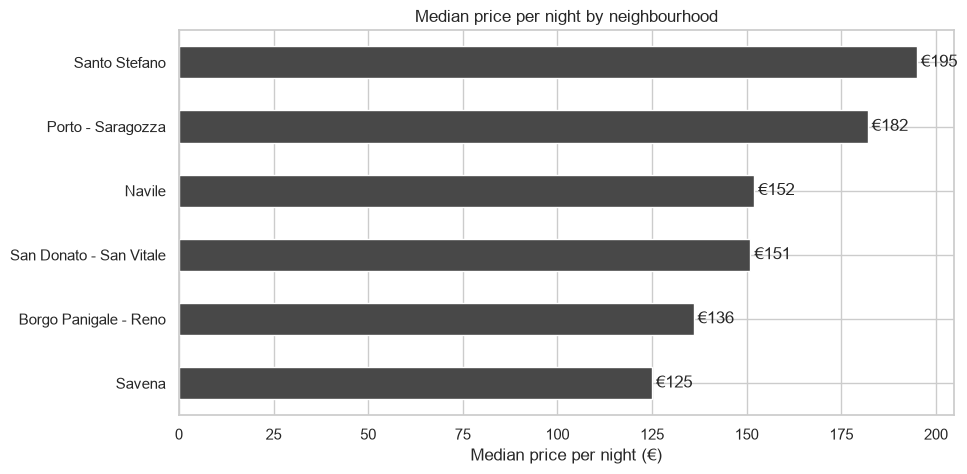

In [30]:
# median price in each neighbourhood
area_price = df.groupby("neighbourhood")["price"].median().sort_values()
ax = area_price.plot(kind="barh", color=dark)
ax.bar_label(ax.containers[0], fmt="€%.0f", padding=3)
ax.set_title("Median price per night by neighbourhood")
ax.set_xlabel("Median price per night (€)")
ax.set_ylabel("")
plt.show()

**Figure 8: median price by neighbourhood.** Santo Stefano (**€195**) and Porto - Saragozza (**€182**) in the centre are the most expensive. Savena (**€125**) is the cheapest, so staying outside the centre can save up to **€70 a night**.

#### G3. How much more is an entire home than a private room?

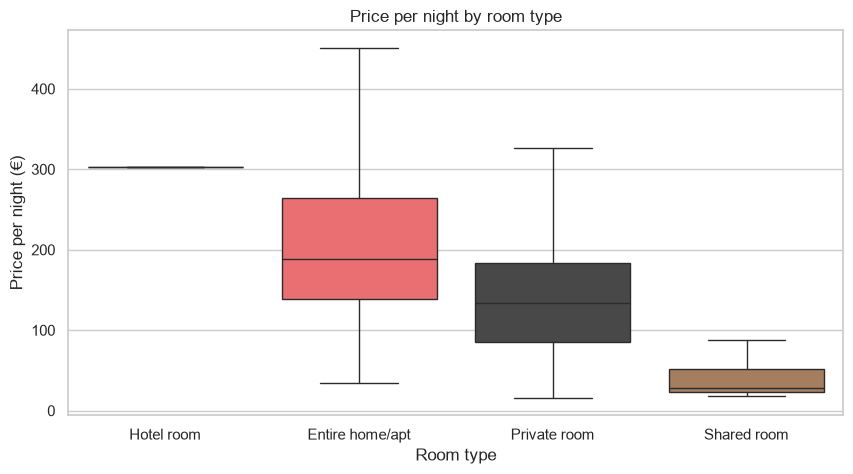

,count,median
room_type,,
Entire home/apt,3534,189.0
Private room,983,134.0
Shared room,12,28.5
Hotel room,1,303.0


In [31]:
# compare the price of each room type (outlier dots hidden)
order = df.groupby("room_type")["price"].median().sort_values(ascending=False).index
ax = sns.boxplot(data=df, x="room_type", y="price", order=order, hue="room_type", palette=room_colors,
                 legend=False, dodge=False, showfliers=False)
ax.set_title("Price per night by room type")
ax.set_xlabel("Room type")
ax.set_ylabel("Price per night (€)")
plt.show()

df.groupby("room_type")["price"].agg(["count", "median"]).sort_values("count", ascending=False)

**Figure 9: price by room type.** An entire home has a median price of **€189** and a private room **€134**, so a private room saves about **€55 a night (29%)**. Shared rooms (12 listings) and hotel rooms (1 listing) are too rare to draw conclusions from.

#### G4. Can I find short stays?

In [32]:
# count short and long stays and check the availability
print(df["stay_type"].value_counts())
print("median available days:", df["availability_365"].median())

stay_type
Short-term                4201
Long-term (30+ nights)     329
Name: count, dtype: int64
median available days: 179.0


4,201 listings (93%) accept short stays, but **329 listings (7%)** need at least 30 nights, so guests should check the minimum stay before booking. The median listing is open **179 days** in the next year.

#### G5. Where are the listings on the map?

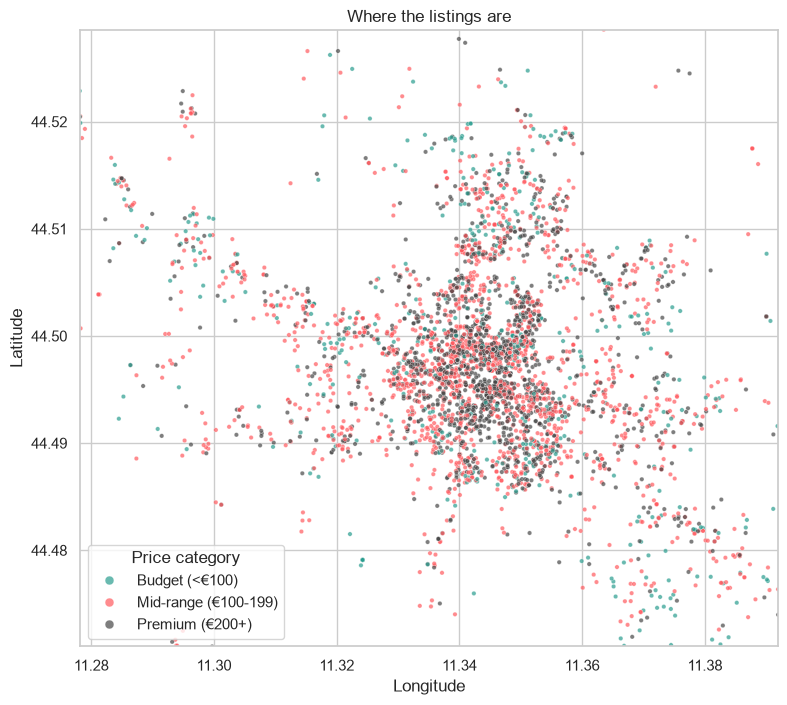

price_category,Budget (<€100),Mid-range (€100-199),Premium (€200+)
neighbourhood,,,
Borgo Panigale - Reno,0.24,0.55,0.21
Navile,0.20,0.48,0.32
Porto - Saragozza,0.08,0.50,0.42
San Donato - San Vitale,0.17,0.52,0.32
Santo Stefano,0.10,0.43,0.47
Savena,0.32,0.48,0.20


In [33]:
# map of the listings coloured by price category
plt.figure(figsize=(9, 8))
ax = sns.scatterplot(data=df, x="longitude", y="latitude", hue="price_category", palette=price_colors,
                     s=10, alpha=0.7)
ax.set_xlim(df["longitude"].quantile(0.01), df["longitude"].quantile(0.99))
ax.set_ylim(df["latitude"].quantile(0.01), df["latitude"].quantile(0.99))
ax.set_title("Where the listings are")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Price category", markerscale=2)
plt.show()

df.groupby("neighbourhood")["price_category"].value_counts(normalize=True).unstack().round(2)

**Figure 10: map of the listings.** The dark premium dots are packed in the centre. The table confirms it: premium listings are **47%** of Santo Stefano and **42%** of Porto - Saragozza, while budget listings are only 8% to 10% there. In the outer neighbourhoods budget listings are much more common: **32%** in Savena and **24%** in Borgo Panigale - Reno.

### 5C. Correlation heatmap

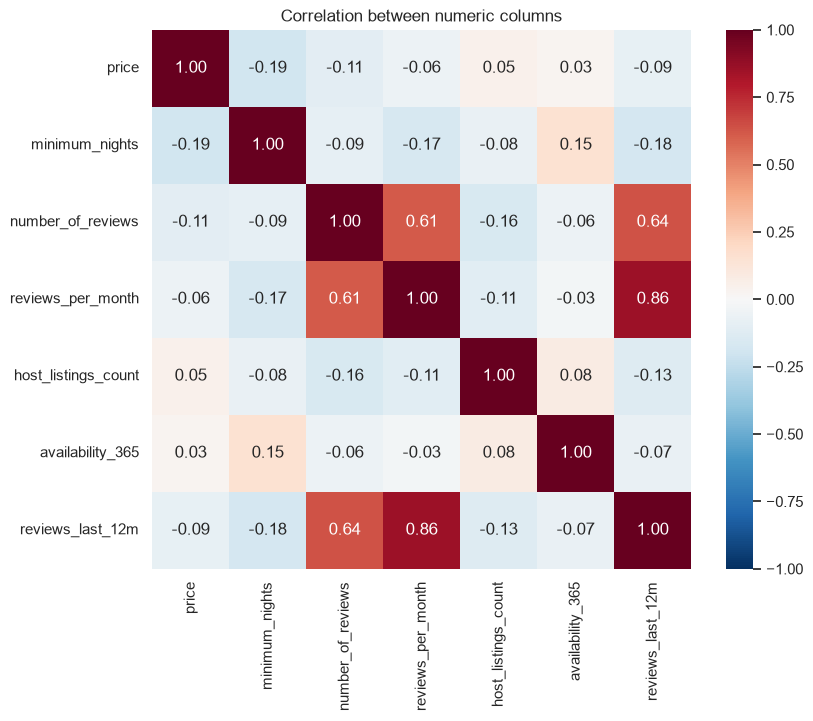

In [34]:
# correlation between the numeric columns
num_cols = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month",
            "host_listings_count", "availability_365", "reviews_last_12m"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation between numeric columns")
plt.show()

**Figure 11: correlation heatmap.**
- `reviews_per_month` and `reviews_last_12m`: **0.86**, strong, because both measure how active a listing is.
- `number_of_reviews` and `reviews_last_12m`: **0.64**, moderate.
- `price` and `reviews_last_12m`: **-0.09**, almost no relationship.
- `minimum_nights` and `reviews_last_12m`: **-0.18**, weak: listings with long minimum stays get a few less reviews.
- `price` is not strongly linked to any numeric column, so it depends more on things like neighbourhood and room type.

### 5D. Univariate analysis

These charts look at one column at a time. They are only in this notebook, not in the dashboard.

#### Histograms of the other numeric columns

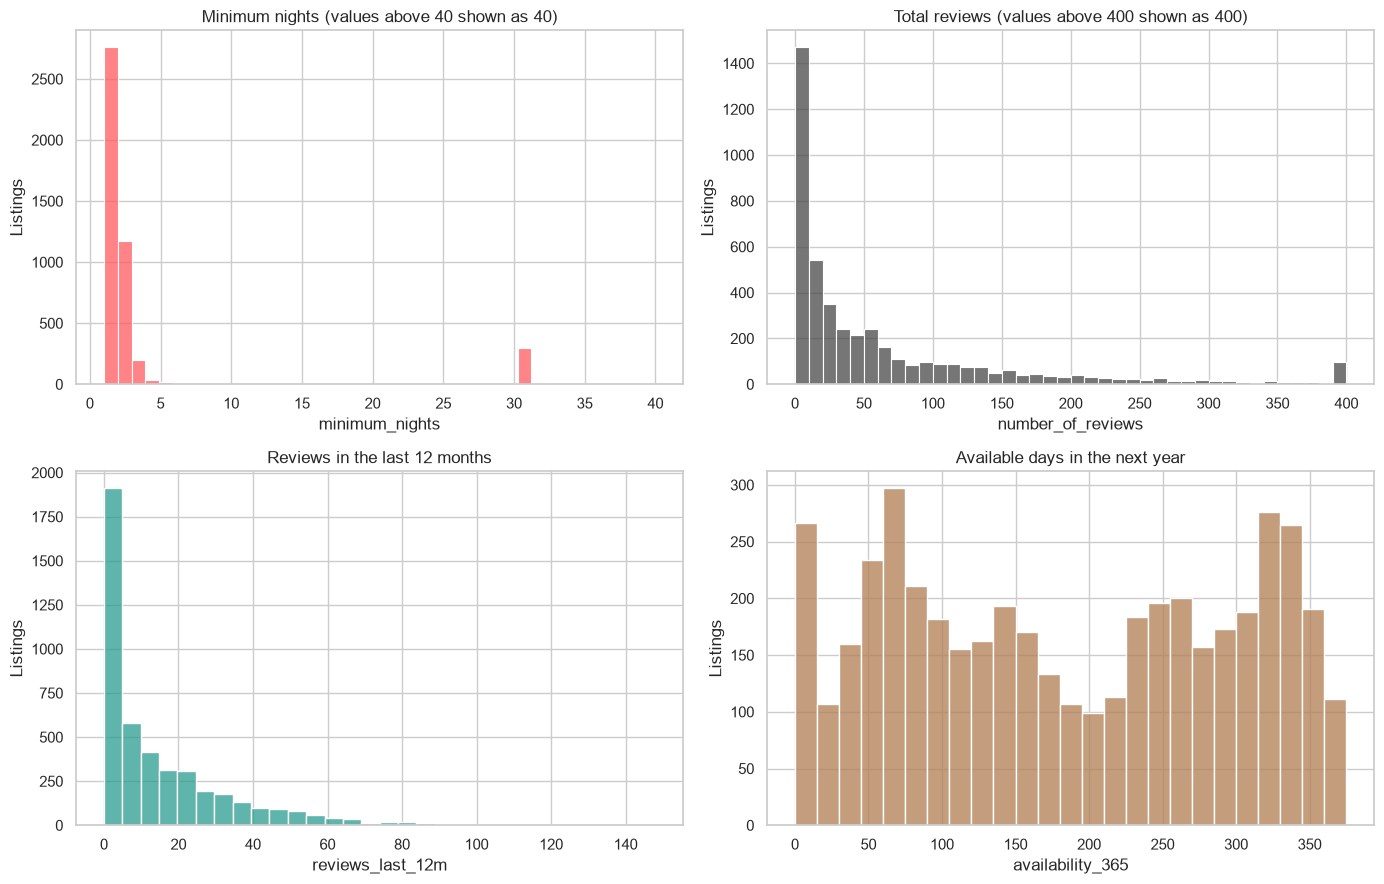

accept 1 night: 61 %
no reviews in the last 12 months: 924
open 300 days or more: 1031


In [35]:
# histograms of the other numeric columns
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(df["minimum_nights"].clip(upper=40), bins=40, color=coral, ax=axes[0, 0])
axes[0, 0].set_title("Minimum nights (values above 40 shown as 40)")
sns.histplot(df["number_of_reviews"].clip(upper=400), bins=40, color=dark, ax=axes[0, 1])
axes[0, 1].set_title("Total reviews (values above 400 shown as 400)")
sns.histplot(df["reviews_last_12m"], bins=30, color=teal, ax=axes[1, 0])
axes[1, 0].set_title("Reviews in the last 12 months")
sns.histplot(df["availability_365"], bins=range(0, 380, 15), color=tan, ax=axes[1, 1])
axes[1, 1].set_title("Available days in the next year")
for ax in axes.flat:
    ax.set_ylabel("Listings")
plt.tight_layout()
plt.show()

print("accept 1 night:", round((df["minimum_nights"] == 1).mean() * 100), "%")
print("no reviews in the last 12 months:", (df["reviews_last_12m"] == 0).sum())
print("open 300 days or more:", (df["availability_365"] >= 300).sum())

**Figure 12: histograms.**
- **Minimum nights:** 61% of the listings accept a 1 night stay and 87% accept 1 or 2 nights. There is a small group at 30 nights or more (the long stays).
- **Total reviews:** very right skewed, with a median of 26 but a maximum of 1,099.
- **Reviews in the last 12 months:** median of 7, and **924 listings (20%)** had no review at all in the last year.
- **Available days:** spread over the whole year with a median of 179. 1,031 listings (23%) are open 300 days or more, and 149 show 0 free days.

#### Countplots of the categorical columns

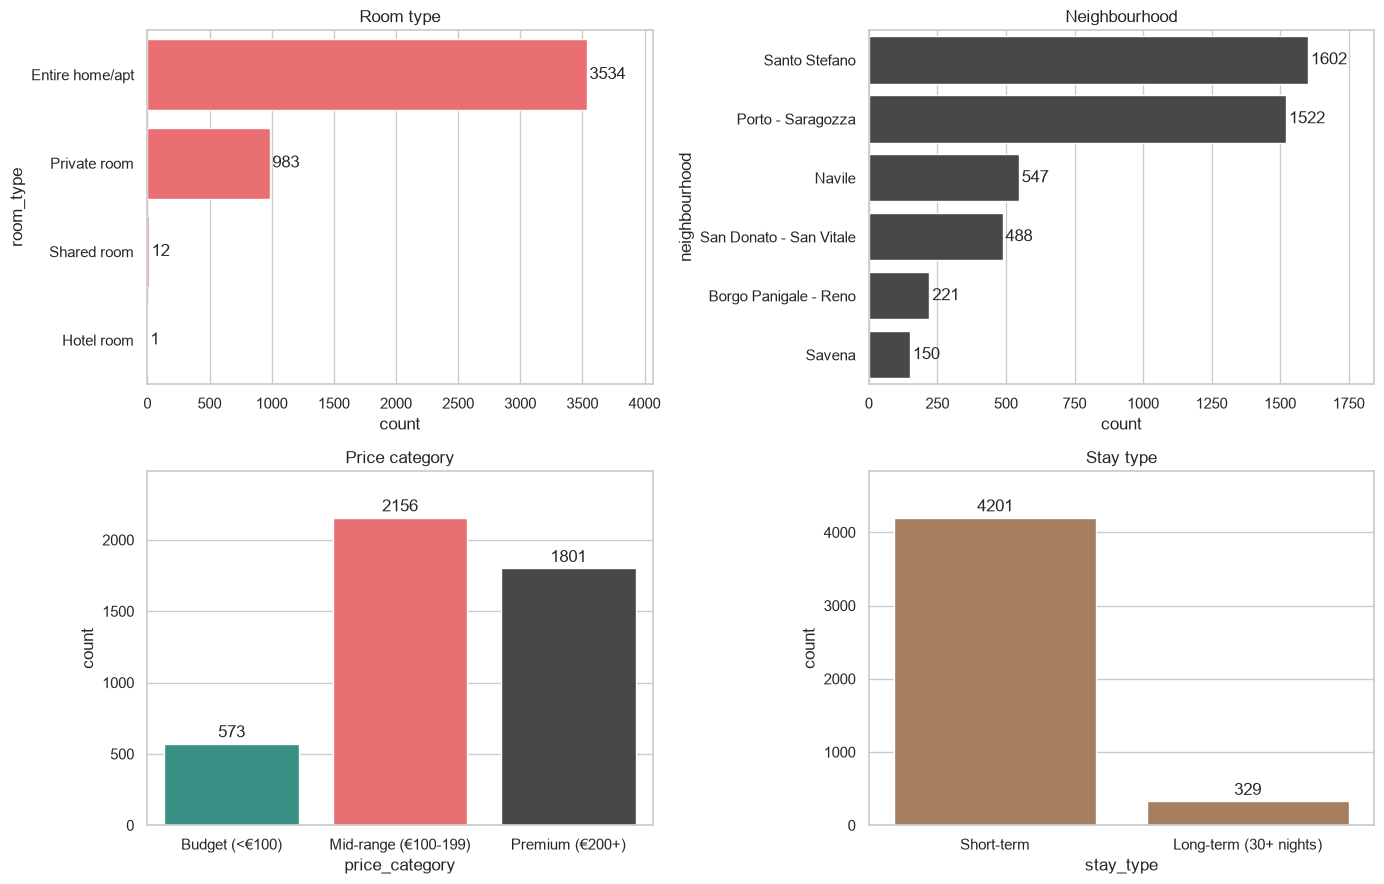

In [36]:
# countplots of the categorical columns
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(data=df, y="room_type", order=df["room_type"].value_counts().index, color=coral, ax=axes[0, 0])
sns.countplot(data=df, y="neighbourhood", order=df["neighbourhood"].value_counts().index, color=dark, ax=axes[0, 1])
sns.countplot(data=df, x="price_category", hue="price_category", palette=price_colors, legend=False,
              dodge=False, ax=axes[1, 0])
sns.countplot(data=df, x="stay_type", color=tan, ax=axes[1, 1])
titles = ["Room type", "Neighbourhood", "Price category", "Stay type"]
for i, (ax, title) in enumerate(zip(axes.flat, titles)):
    ax.set_title(title)
    for bars in ax.containers:
        ax.bar_label(bars, padding=2)
    # leave space for the labels at the end of the bars
    if i < 2:
        ax.margins(x=0.15)
    else:
        ax.margins(y=0.15)
plt.tight_layout()
plt.show()

**Figure 13: countplots.** Entire homes are most of the market (3,534 listings, 78%), then private rooms (983), shared rooms (12) and only 1 hotel room. Santo Stefano and Porto - Saragozza are by far the biggest areas. Mid-range is the biggest price group (2,156), then premium (1,801) and budget (573). 4,201 listings are short-term and 329 are long-term.

#### Boxplots of the numeric columns

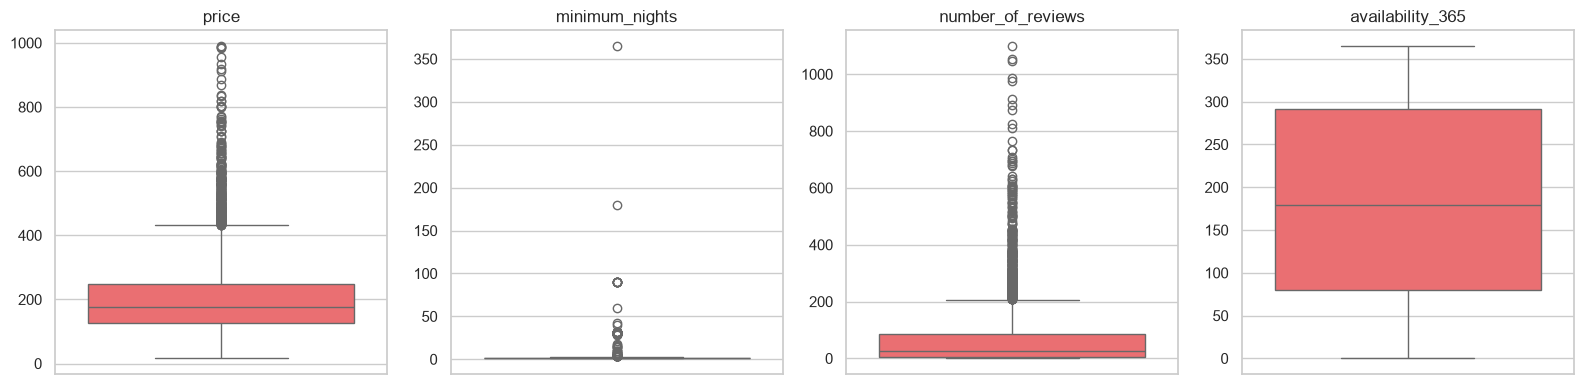

price upper limit: 432.0 outliers: 275
minimum_nights upper limit: 3.5 outliers: 398
number_of_reviews upper limit: 207.5 outliers: 387
availability_365 upper limit: 610.0 outliers: 0


In [37]:
# boxplots of the numeric columns to see the outliers
cols = ["price", "minimum_nights", "number_of_reviews", "availability_365"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color=coral)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

# count the outliers with the 1.5 x iqr rule (all the outliers here are on the high side)
for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    print(col, "upper limit:", upper, "outliers:", (df[col] > upper).sum())

**Figure 14: boxplots.** With the 1.5 x IQR rule, **275 listings (6%)** cost more than €432, **398 listings** ask for more than 3 nights as a minimum, and **387 listings** have more than 207 reviews. These are real listings and not errors, so we keep them; only the extreme prices above €1,000 were removed during cleaning. Availability has no outliers because it is spread over the whole year.

### 5E. Bivariate and multivariate analysis

More charts that compare two or more columns. They are only in this notebook, not in the dashboard.

#### Room type mix in each neighbourhood (stacked bar plot)

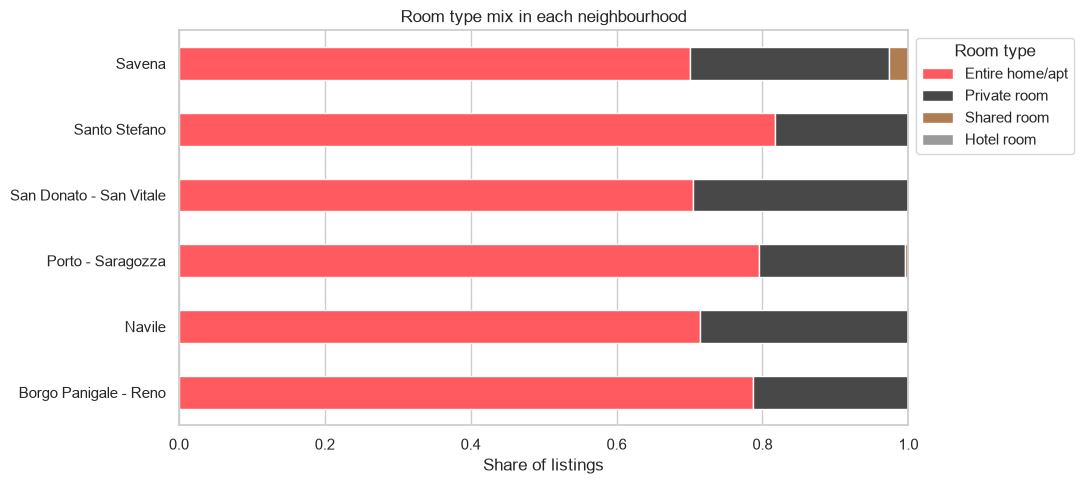

room_type,Entire home/apt,Private room,Shared room,Hotel room
neighbourhood,,,,
Borgo Panigale - Reno,0.79,0.21,0.00,0.0
Navile,0.71,0.29,0.00,0.0
Porto - Saragozza,0.80,0.20,0.00,0.0
San Donato - San Vitale,0.70,0.30,0.00,0.0
Santo Stefano,0.82,0.18,0.00,0.0
Savena,0.70,0.27,0.03,0.0


In [38]:
# share of each room type in each neighbourhood
mix = pd.crosstab(df["neighbourhood"], df["room_type"], normalize="index")
mix = mix[["Entire home/apt", "Private room", "Shared room", "Hotel room"]]
ax = mix.plot(kind="barh", stacked=True, color=[room_colors[c] for c in mix.columns], figsize=(11, 5))
ax.set_title("Room type mix in each neighbourhood")
ax.set_xlabel("Share of listings")
ax.set_ylabel("")
ax.legend(title="Room type", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

mix.round(2)

**Figure 15: room type mix.** Entire homes are the majority in every area, from 70% in Savena to 82% in Santo Stefano. Private rooms are more common outside the centre: 30% in San Donato - San Vitale and 29% in Navile, against 18% in Santo Stefano.

#### Available days vs demand (scatter plot)

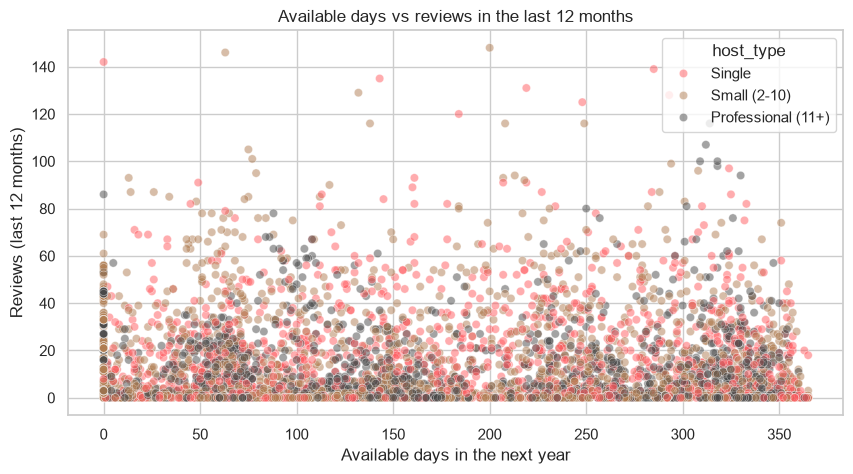

correlation: -0.07


,availability_365,reviews_last_12m
host_type,,
Single,190.6,17.4
Small (2-10),172.2,14.9
Professional (11+),196.2,12.9


In [39]:
# available days against reviews in the last 12 months, by host type
ax = sns.scatterplot(data=df, x="availability_365", y="reviews_last_12m", hue="host_type", palette=host_colors,
                     alpha=0.5)
ax.set_title("Available days vs reviews in the last 12 months")
ax.set_xlabel("Available days in the next year")
ax.set_ylabel("Reviews (last 12 months)")
plt.show()

print("correlation:", round(df["availability_365"].corr(df["reviews_last_12m"]), 2))
df.groupby("host_type", observed=True)[["availability_365", "reviews_last_12m"]].mean().round(1)

**Figure 16: available days vs demand.** There is almost no relationship (correlation **-0.07**): listings with many free days are not clearly less booked. Professional hosts keep their listings open a bit longer (196 days on average) than small hosts (172), but they get fewer reviews (12.9 against 17.4 for single hosts).

#### Median price by neighbourhood and room type (heatmap)

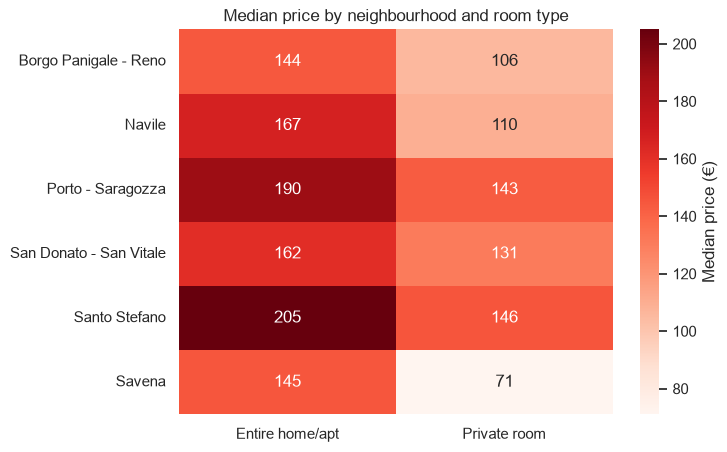

In [40]:
# median price for each neighbourhood and room type
# shared and hotel rooms are left out because there are too few of them
main_rooms = df[df["room_type"].isin(["Entire home/apt", "Private room"])]
pivot = main_rooms.pivot_table(index="neighbourhood", columns="room_type", values="price", aggfunc="median")
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "Median price (€)"})
plt.title("Median price by neighbourhood and room type")
plt.xlabel("")
plt.ylabel("")
plt.show()

**Figure 17: price by neighbourhood and room type.** The cheapest choice in the city is a private room in Savena (median **€71**) and the most expensive is an entire home in Santo Stefano (**€205**). An entire home costs more than a private room in every area, from about €30 more in San Donato - San Vitale to €74 more in Savena.

#### Pairplot of the main numeric columns

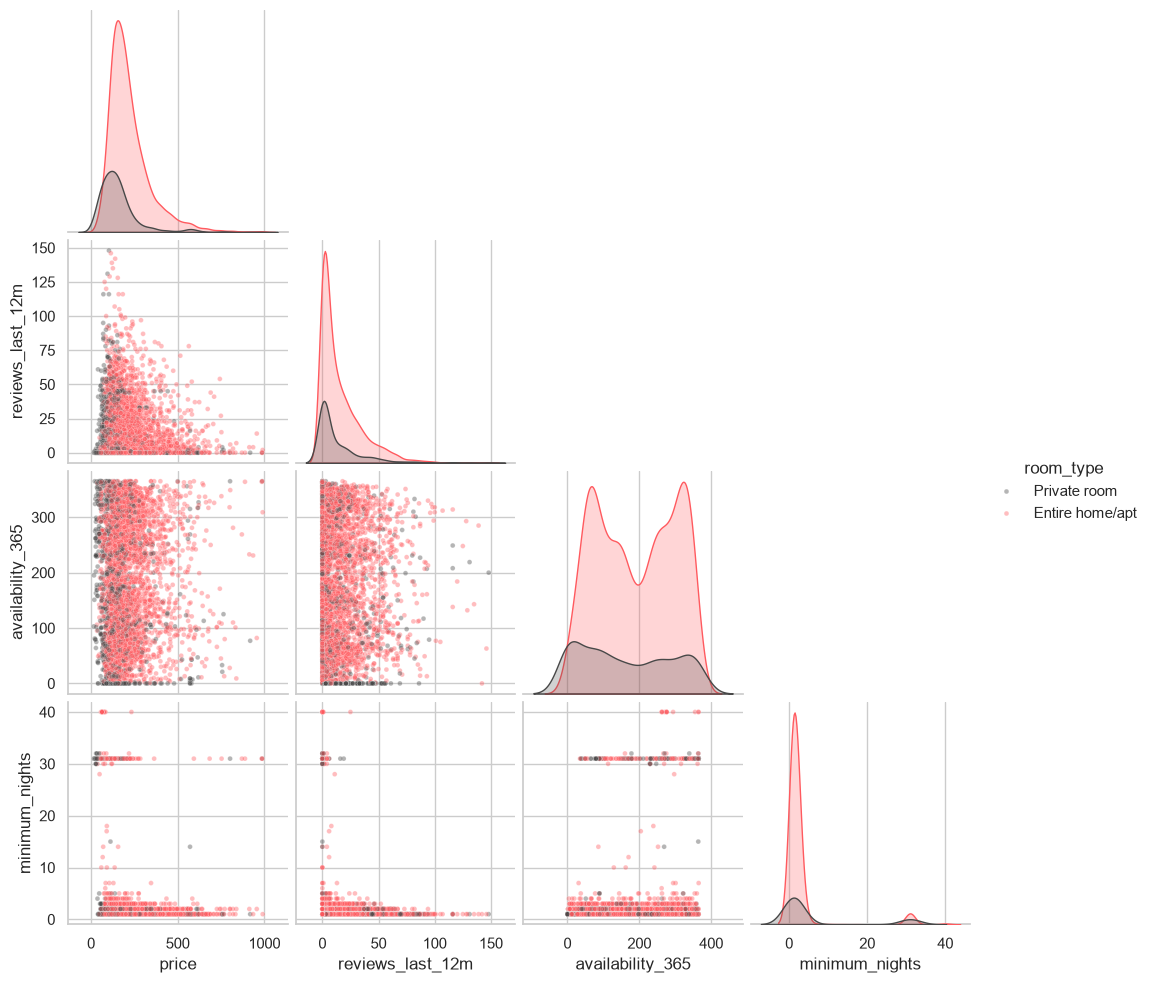

In [41]:
# pairplot of four numeric columns, coloured by room type
cols = ["price", "reviews_last_12m", "availability_365", "minimum_nights"]
pairs = main_rooms[cols + ["room_type"]].copy()
# show minimum nights above 40 as 40 so a few very long stays do not squash the chart
pairs["minimum_nights"] = pairs["minimum_nights"].clip(upper=40)
sns.pairplot(pairs, hue="room_type", palette=room_colors, corner=True, plot_kws={"alpha": 0.4, "s": 12})
plt.show()

**Figure 18: pairplot.** The pairplot shows every pair of these columns at once. Entire homes (coral) sit at higher prices than private rooms (dark) in the price panels, and no pair forms a clear line. This matches the heatmap: price has only weak correlations with the other columns (between -0.19 and 0.03).

## 6. Price prediction model

Can we predict a listing's price from this file? We train a **Random Forest** (many decision trees whose answers are averaged) and compare it with a **baseline** that always guesses the median price. The same model is used in the price predictor of the Streamlit dashboard.

**Steps**
1. Add one feature: the **distance to Piazza Maggiore**, Bologna's main square.
2. Split the listings: **80%** to train the model and **20%** to test it on listings it has never seen.
3. Train on **log(price)** because prices are right skewed, then change the predictions back to euros.
4. Measure the error with **MAE** (the average difference in €) and **R2** (the share of the price differences the model explains).

In [42]:
# distance from piazza maggiore in km
centre_lat, centre_lon = 44.49381, 11.34265
df["km_to_centre"] = (111.32 * np.hypot(df["latitude"] - centre_lat,
                                        (df["longitude"] - centre_lon) * np.cos(np.radians(centre_lat)))).round(2)
df["km_to_centre"].describe().round(2)

count    4530.00
mean        1.56
std         1.28
min         0.04
25%         0.65
50%         1.10
75%         2.13
max         9.42
Name: km_to_centre, dtype: float64

Half of the listings are within **1.1 km** of the main square and the farthest one is about 9 km away.

In [43]:
# choose the features and split the data 80 / 20
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

cat_features = ["neighbourhood", "room_type"]
num_features = ["km_to_centre", "minimum_nights", "number_of_reviews", "reviews_last_12m",
                "availability_365", "host_listings_count"]
X = df[cat_features + num_features]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", len(X_train), "test:", len(X_test))

train: 3624 test: 906


In [44]:
# train the random forest and compare it with the baseline
model = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)],
                               remainder="passthrough")),
    ("forest", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)),
])
model.fit(X_train, np.log(y_train))
y_pred = np.exp(model.predict(X_test))

baseline = np.full(len(y_test), y_train.median())
mae_model = mean_absolute_error(y_test, y_pred)
mae_baseline = mean_absolute_error(y_test, baseline)
print("baseline mae:", round(mae_baseline))
print("random forest mae:", round(mae_model))
print("improvement:", round((1 - mae_model / mae_baseline) * 100), "%")
print("r2:", round(r2_score(y_test, y_pred), 2))

baseline mae: 88
random forest mae: 73
improvement: 17 %
r2: 0.16


The Random Forest's average error is **€73** per night against **€88** for the baseline, so it is **17% better**. But the **R2 of 0.16** shows that it explains only a small part of the price differences.

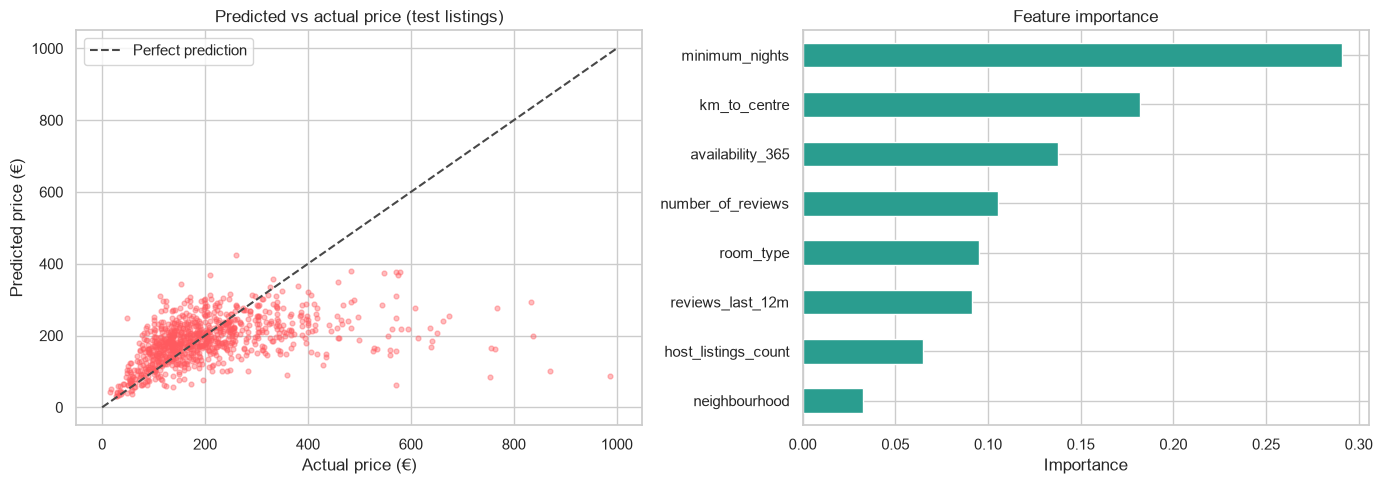

minimum_nights         0.29
km_to_centre           0.18
availability_365       0.14
number_of_reviews      0.11
room_type              0.10
reviews_last_12m       0.09
host_listings_count    0.06
neighbourhood          0.03
dtype: float64

In [45]:
# predicted vs actual price and the importance of each feature
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred, alpha=0.4, s=12, color=coral)
axes[0].plot([0, 1000], [0, 1000], linestyle="--", color=dark, label="Perfect prediction")
axes[0].set_title("Predicted vs actual price (test listings)")
axes[0].set_xlabel("Actual price (€)")
axes[0].set_ylabel("Predicted price (€)")
axes[0].legend()

# add the one hot columns back together so each feature gets one number
names = model.named_steps["prep"].get_feature_names_out()
importance = pd.Series(model.named_steps["forest"].feature_importances_, index=names)
importance = importance.groupby(lambda n: next(f for f in cat_features + num_features if f in n)).sum()
importance.sort_values().plot(kind="barh", ax=axes[1], color=teal)
axes[1].set_title("Feature importance")
axes[1].set_xlabel("Importance")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(2)

**Figure 19: model results.** Left: the dots follow the dashed line for cheap and mid-range listings, but the model clearly under-predicts the expensive ones, because it cannot see what makes them expensive. Right: **minimum nights** and **distance to the centre** are the most useful features, while the neighbourhood adds little once the distance is known.

**Why is the model limited?** The file has no size, number of bedrooms, amenities or photos, and those drive much of an Airbnb price.

In [46]:
# try the model on one example listing
example = pd.DataFrame([{"neighbourhood": "Santo Stefano", "room_type": "Entire home/apt", "km_to_centre": 0.8,
                         "minimum_nights": 2, "number_of_reviews": 20, "reviews_last_12m": 8,
                         "availability_365": 180, "host_listings_count": 1}])
print("estimated price:", round(np.exp(model.predict(example)[0])), "euros per night")

estimated price: 206 euros per night


## 7. Insights summary

### Patterns
- Prices are right skewed: a typical night costs **€176** and half of the listings cost **€127 to €249**.
- **69%** of the listings are in two central neighbourhoods (Santo Stefano and Porto - Saragozza).
- **78%** of the listings are entire homes and **93%** accept short stays; 61% even accept a single night.
- **20%** of the listings had no review in the last 12 months.
- Entire homes are the majority in every neighbourhood, but private rooms are more common outside the centre.

### Interesting relationships
- **Mid-range listings get the most demand:** a median of 10 reviews a year against 3 for budget listings.
- **Professional hosts charge more but get fewer reviews:** €194 vs €163 median price, and 12.9 vs 17.4 reviews a year.
- **Price and demand are almost unrelated** (correlation -0.09).
- **Price is hard to predict from this file alone:** the model is 17% better than guessing the median (€73 vs €88 average error) but explains only 16% of the price differences.

### Outliers
- **44 listings** asked more than €1,000 a night (up to €10,000). They were removed.
- **329 listings** need a minimum stay of 30 nights or more (up to 365). They were kept and marked as long-term.
- **448 listings** have never been reviewed.
- With the 1.5 x IQR rule, 275 listings (6%) cost more than €432 and 387 listings have more than 207 reviews. They are real listings, so they were kept.

### Key takeaways

| For hosts | For guests |
|---|---|
| Price in the **mid-range (€100 to €199)**: it gets the most demand. | Choose a **private room** to save about **€55 a night**. |
| **Porto - Saragozza** has a high median price (€182) and the highest demand (17.2 reviews a year on average). | Stay **outside the centre** (Savena €125 vs Santo Stefano €195) to save up to **€70 a night**. |
| The centre is crowded: **69%** of the competition is there. | **Check the minimum stay**: 7% of listings only accept 30 nights or more. |

## 8. Final summary

### Main insights
Bologna's Airbnb market is concentrated in the historic centre and partly run by a small number of professional hosts (48 hosts run 28% of the listings). For **hosts**, the mid-range price (€100 to €199) attracts the most guests. For **guests**, a private room or a neighbourhood outside the centre gives the best value.

### What I learned
- How to load, explore and clean a real dataset with pandas: missing values, duplicates, data types, outliers and new columns.
- Cleaning decisions change the results, so every step must be explained (for example, why missing prices were removed but missing `reviews_per_month` values became 0).
- For skewed data like prices, the **median** describes a typical value better than the mean.
- How to train and test a simple machine learning model and compare it with a baseline so the result is honest.
- Looking at the same data from two points of view (host and guest) turns one table into a clear story.

### Limitations of the dataset
- It is **one snapshot** (19 September 2026), so it does not show the seasons.
- Prices are **listed prices**, not what guests really paid.
- Reviews are only a **proxy** for demand: not every guest leaves a review.
- **10%** of the listings had no price and had to be removed.

### Recommendations for future analysis
- Compare several snapshots to see how prices change across the seasons.
- Compare Bologna with other Italian cities.
- Use the detailed Inside Airbnb file (`listings.csv.gz`), which adds review scores, amenities and the number of bedrooms.
- Improve the price model with those extra features; size and amenities should raise the R2 a lot.